# Territory of Chr11 nuclear localization

In [6]:
import numpy as np
import pandas as pd
import tifffile as tiff
import cv2
import matplotlib.pyplot as plt
import glob
import os

from skimage import color, morphology, measure
from skimage.measure import regionprops
from scipy.ndimage import distance_transform_edt


In [2]:
# -------------------------
# Load channel
# -------------------------
def load_image_tifffile(path, channel):
    image = tiff.imread(path)
    if len(image.shape) == 3 and channel < image.shape[0]:
        return image[channel]
    else:
        raise IndexError(f"Channel {channel} is out of bounds for image with shape {image.shape}")


# -------------------------
# Edge coordinates
# -------------------------
def get_binary_edges_and_coordinates(binary_image, region_labels):
    edges = cv2.Canny(binary_image, threshold1=50, threshold2=150)
    edge_coords = np.column_stack(np.where(edges > 0))

    valid_indices = (
        (edge_coords[:, 0] < region_labels.shape[0]) &
        (edge_coords[:, 1] < region_labels.shape[1])
    )
    edge_coords = edge_coords[valid_indices]

    labels_at_edges = region_labels[edge_coords[:, 0], edge_coords[:, 1]]

    df_edges = pd.DataFrame(edge_coords, columns=["Edge_Y", "Edge_X"])
    df_edges["Region_Label"] = labels_at_edges
    return df_edges

# -------------------------
# Nucleus extraction
# your logic + keep largest nucleus
# skip cell if no nuclear signal
# -------------------------
def extract_nuclear_morphology(
    image,
    min_nuclear_signal_pixels=1000,
    min_nuclear_signal_intensity=0
):
    gray_image = color.rgb2gray(image) if len(image.shape) == 3 else image.astype(np.float32)

    gray_image = gray_image - gray_image.min()
    if gray_image.max() > 0:
        gray_image = gray_image / gray_image.max()
    else:
        raise ValueError("No nuclear signal: image has zero intensity range.")

    # -------------------------
    # NEW: skip if no nuclear signal
    # -------------------------
    nuclear_signal_pixels = gray_image > min_nuclear_signal_intensity
    n_nuclear_signal_pixels = np.sum(nuclear_signal_pixels)

    if n_nuclear_signal_pixels < min_nuclear_signal_pixels:
        raise ValueError(
            f"No nuclear signal: only {n_nuclear_signal_pixels} pixels > {min_nuclear_signal_intensity}"
        )

    equalized_image = cv2.equalizeHist((gray_image * 255).astype(np.uint8))

    # blur before threshold
    blurred_image = cv2.GaussianBlur(equalized_image, (0, 0), 3)
    normalized_image = blurred_image / 255.0

    nuclear_threshold = np.percentile(normalized_image.flatten(), 90)
    nuclear_mask = normalized_image >= nuclear_threshold
    nuclear_mask = morphology.remove_small_objects(nuclear_mask, min_size=20000)
    nuclear_mask = morphology.remove_small_holes(nuclear_mask, area_threshold=5000)

    labeled_nuclei, num_labels = measure.label(nuclear_mask, connectivity=2, return_num=True)

    if num_labels == 0:
        raise ValueError("No nucleus detected after thresholding.")

    props = measure.regionprops(labeled_nuclei)
    largest_region = max(props, key=lambda r: r.area)

    if largest_region.area < 20000:
        raise ValueError(f"No valid nucleus detected: largest area = {largest_region.area}")

    largest_label = largest_region.label
    nuclear_mask = labeled_nuclei == largest_label

    # smooth/fill envelope
    nuclear_mask = morphology.binary_closing(nuclear_mask, morphology.disk(5))
    nuclear_mask = morphology.remove_small_holes(nuclear_mask, area_threshold=100000)

    labeled_nuclei, num_labels = measure.label(nuclear_mask, connectivity=2, return_num=True)

    df_nuclear_edges = get_binary_edges_and_coordinates(
        nuclear_mask.astype(np.uint8) * 255,
        labeled_nuclei
    )
    df_nuclear_edges = df_nuclear_edges[df_nuclear_edges["Region_Label"] > 0]

    return labeled_nuclei, num_labels, df_nuclear_edges


# -------------------------
# Nuclear centroid
# -------------------------
def calculate_nuclear_centroid(nuclear_region, nuclear_image):
    regions = regionprops(nuclear_region, intensity_image=nuclear_image)

    if len(regions) == 0:
        raise ValueError("No nuclear region found for centroid calculation.")

    centroid = regions[0].centroid
    return centroid[0], centroid[1]


# -------------------------
# CT mask extraction
# skip cell if no CT signal inside nucleus
# -------------------------
def extract_ct_mask(
    ct_image,
    nucleus_mask,
    threshold_percentile=90,
    min_size=30,
    min_signal_pixels=10,
    min_signal_intensity=0
):
    ct_image = ct_image.astype(np.float32)
    ct_inside = ct_image[nucleus_mask]

    if ct_inside.size == 0:
        raise ValueError("Nucleus mask is empty.")

    # -------------------------
    # NEW: skip if no signal inside nucleus
    # -------------------------
    signal_pixels = ct_inside > min_signal_intensity
    n_signal_pixels = np.sum(signal_pixels)

    if n_signal_pixels < min_signal_pixels:
        raise ValueError(
            f"No CT signal inside nucleus: only {n_signal_pixels} pixels > {min_signal_intensity}"
        )

    # use only nuclear pixels to define threshold
    thr = np.percentile(ct_inside, threshold_percentile)
    ct_mask = (ct_image >= thr) & nucleus_mask

    ct_mask = morphology.remove_small_objects(ct_mask, min_size=min_size)
    ct_mask = morphology.remove_small_holes(ct_mask, area_threshold=20)

    # -------------------------
    # NEW: skip if thresholded CT mask is empty
    # -------------------------
    if ct_mask.sum() == 0:
        raise ValueError("No CT mask detected after thresholding.")

    return ct_mask


# -------------------------
# Get largest contour
# -------------------------
def get_largest_nucleus_contour(nucleus_mask):
    mask_uint8 = (nucleus_mask.astype(np.uint8) * 255)
    contours, _ = cv2.findContours(mask_uint8, cv2.RETR_EXTERNAL, cv2.CHAIN_APPROX_NONE)

    if len(contours) == 0:
        raise ValueError("No contour found for nucleus mask.")

    largest_contour = max(contours, key=cv2.contourArea)
    return largest_contour


# -------------------------
# Build contour-based radial zones
# -------------------------
def build_contour_based_nuclear_zones(nucleus_mask, centroid_y, centroid_x):
    """
    Build contour-based radial zones:
      center:   radial_position < 0.5
      middle:   0.5 <= radial_position < 0.7
      periphery: 0.7 <= radial_position <= 1.0

    radial_position is computed from centroid outward to nuclear contour.
    """
    contour = get_largest_nucleus_contour(nucleus_mask)

    yy, xx = np.where(nucleus_mask)
    coords = np.column_stack([yy, xx])

    # contour points: OpenCV gives (x, y)
    contour_xy = contour[:, 0, :]   # shape (N, 2)
    contour_x = contour_xy[:, 0]
    contour_y = contour_xy[:, 1]

    # angle of contour points around centroid
    contour_angles = np.arctan2(contour_y - centroid_y, contour_x - centroid_x)
    contour_radii = np.sqrt((contour_y - centroid_y)**2 + (contour_x - centroid_x)**2)

    # sort by angle
    order = np.argsort(contour_angles)
    contour_angles = contour_angles[order]
    contour_radii = contour_radii[order]

    # close the angular curve for interpolation
    contour_angles_ext = np.concatenate([
        contour_angles - 2*np.pi,
        contour_angles,
        contour_angles + 2*np.pi
    ])
    contour_radii_ext = np.concatenate([
        contour_radii,
        contour_radii,
        contour_radii
    ])

    # pixel angles/radii
    pix_y = coords[:, 0]
    pix_x = coords[:, 1]

    pix_angles = np.arctan2(pix_y - centroid_y, pix_x - centroid_x)
    pix_radii = np.sqrt((pix_y - centroid_y)**2 + (pix_x - centroid_x)**2)

    # interpolate boundary radius at each pixel angle
    boundary_radii = np.interp(pix_angles, contour_angles_ext, contour_radii_ext)

    radial_position = np.zeros(nucleus_mask.shape, dtype=float)
    radial_position[:] = np.nan
    radial_position[pix_y, pix_x] = pix_radii / boundary_radii

    # numerical clipping
    radial_position = np.clip(radial_position, 0, 1)

    center_mask = nucleus_mask & (radial_position < 0.5)
    middle_mask = nucleus_mask & (radial_position >= 0.5) & (radial_position < 0.7)
    periphery_mask = nucleus_mask & (radial_position >= 0.7)

    return radial_position, center_mask, middle_mask, periphery_mask


# -------------------------
# Quantify CT fraction in each zone
# -------------------------
def quantify_ct_zone_fraction(ct_mask, periphery_mask, center_mask, middle_mask):
    total_ct = ct_mask.sum()

    if total_ct == 0:
        return {
            "CT_total_pixels": 0,
            "CT_periphery_pixels": 0,
            "CT_center_pixels": 0,
            "CT_middle_pixels": 0,
            "fraction_periphery": np.nan,
            "fraction_center": np.nan,
            "fraction_middle": np.nan
        }

    ct_periphery = (ct_mask & periphery_mask).sum()
    ct_center = (ct_mask & center_mask).sum()
    ct_middle = (ct_mask & middle_mask).sum()

    return {
        "CT_total_pixels": int(total_ct),
        "CT_periphery_pixels": int(ct_periphery),
        "CT_center_pixels": int(ct_center),
        "CT_middle_pixels": int(ct_middle),
        "fraction_periphery": ct_periphery / total_ct,
        "fraction_center": ct_center / total_ct,
        "fraction_middle": ct_middle / total_ct
    }


# -------------------------
# Visualization
# -------------------------
def show_zone_classification(nucleus_mask, ct_mask, center_mask, middle_mask, periphery_mask, title=""):
    zone_img = np.zeros((*nucleus_mask.shape, 3), dtype=np.uint8)

    # center = blue
    zone_img[center_mask] = [0, 0, 255]
    # middle = green
    zone_img[middle_mask] = [0, 180, 0]
    # periphery = red
    zone_img[periphery_mask] = [255, 0, 0]

    overlay = zone_img.copy()
    overlay[ct_mask] = [255, 255, 0]  # CT = yellow

    fig, axes = plt.subplots(1, 3, figsize=(12, 4))

    axes[0].imshow(nucleus_mask, cmap="gray")
    axes[0].set_title("Nucleus mask")
    axes[0].axis("off")

    axes[1].imshow(zone_img)
    axes[1].set_title("Zones\nBlue=center, Green=middle, Red=periphery")
    axes[1].axis("off")

    axes[2].imshow(overlay)
    axes[2].set_title(f"CT overlay\n{title}")
    axes[2].axis("off")

    plt.tight_layout()
    plt.show()


# -------------------------
# Single image analysis
# -------------------------
def analyze_ct_localization_by_nuclear_zone(
    image_file,
    nucleus_channel,
    ct_channel,
    ct_threshold_percentile=90,
    ct_min_size=30,
    min_ct_signal_pixels=10,
    min_ct_signal_intensity=0,
    min_nuclear_signal_pixels=1000,
    min_nuclear_signal_intensity=0,
    show_plot=False
):
    nucleus_img = load_image_tifffile(image_file, nucleus_channel)
    ct_img = load_image_tifffile(image_file, ct_channel)

    labeled_nuclei, num_labels, df_nuclear_edges = extract_nuclear_morphology(
        nucleus_img,
        min_nuclear_signal_pixels=min_nuclear_signal_pixels,
        min_nuclear_signal_intensity=min_nuclear_signal_intensity
    )

    nucleus_mask = labeled_nuclei > 0

    centroid_y, centroid_x = calculate_nuclear_centroid(labeled_nuclei, nucleus_img)

    ct_mask = extract_ct_mask(
        ct_img,
        nucleus_mask,
        threshold_percentile=ct_threshold_percentile,
        min_size=ct_min_size,
        min_signal_pixels=min_ct_signal_pixels,
        min_signal_intensity=min_ct_signal_intensity
    )

    radial_position, center_mask, middle_mask, periphery_mask = build_contour_based_nuclear_zones(
        nucleus_mask,
        centroid_y,
        centroid_x
    )

    result = quantify_ct_zone_fraction(ct_mask, periphery_mask, center_mask, middle_mask)

    result["image_name"] = os.path.basename(image_file)
    result["Centroid_Y"] = centroid_y
    result["Centroid_X"] = centroid_x
    result["nucleus_area"] = int(nucleus_mask.sum())
    result["ct_area"] = int(ct_mask.sum())

    if show_plot:
        show_zone_classification(
            nucleus_mask,
            ct_mask,
            center_mask,
            middle_mask,
            periphery_mask,
            title=os.path.basename(image_file)
        )

    return result

# -------------------------
# Folder analysis
# -------------------------
def analyze_folder_ct_localization(
    image_path,
    nucleus_channel,
    ct_channel,
    ct_threshold_percentile=90,
    ct_min_size=30,
    min_ct_signal_pixels=10,
    min_ct_signal_intensity=0,
    min_nuclear_signal_pixels=1000,
    min_nuclear_signal_intensity=0,
    show_first_n=3
):
    tif_files = sorted(glob.glob(os.path.join(image_path, "*.tif"))) + \
                sorted(glob.glob(os.path.join(image_path, "*.tiff")))

    print(f"Found {len(tif_files)} tif files")

    results = []

    for i, image_file in enumerate(tif_files):
        print(f"[{i+1}/{len(tif_files)}] Processing: {os.path.basename(image_file)}")
        try:
            res = analyze_ct_localization_by_nuclear_zone(
                image_file=image_file,
                nucleus_channel=nucleus_channel,
                ct_channel=ct_channel,
                ct_threshold_percentile=ct_threshold_percentile,
                ct_min_size=ct_min_size,
                min_ct_signal_pixels=min_ct_signal_pixels,
                min_ct_signal_intensity=min_ct_signal_intensity,
                min_nuclear_signal_pixels=min_nuclear_signal_pixels,
                min_nuclear_signal_intensity=min_nuclear_signal_intensity,
                show_plot=(i < show_first_n)
            )
            results.append(res)

        except Exception as e:
            print(f"  [SKIP] {os.path.basename(image_file)} -> {e}")

    return pd.DataFrame(results)

Found 11 tif files
[1/11] Processing: DE_chr11_488_chr11_88_647_chr11_41_550_2_-_Position_31_tif_MIPs_series1_MIP.tif


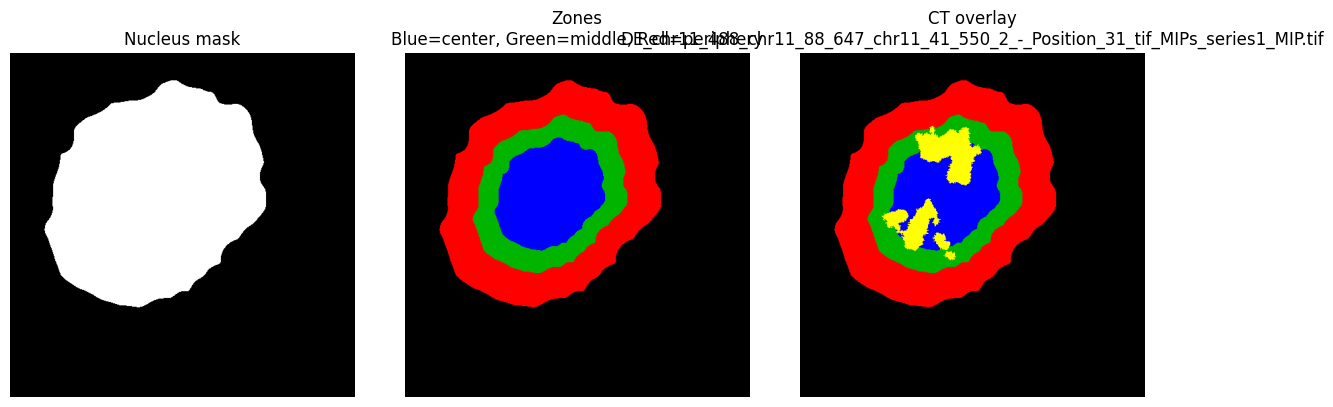

[2/11] Processing: H1_chr11_488_chr11_88_647_chr11_41_550_2_-_Position_37_tif_MIPs_series1_MIP.tif


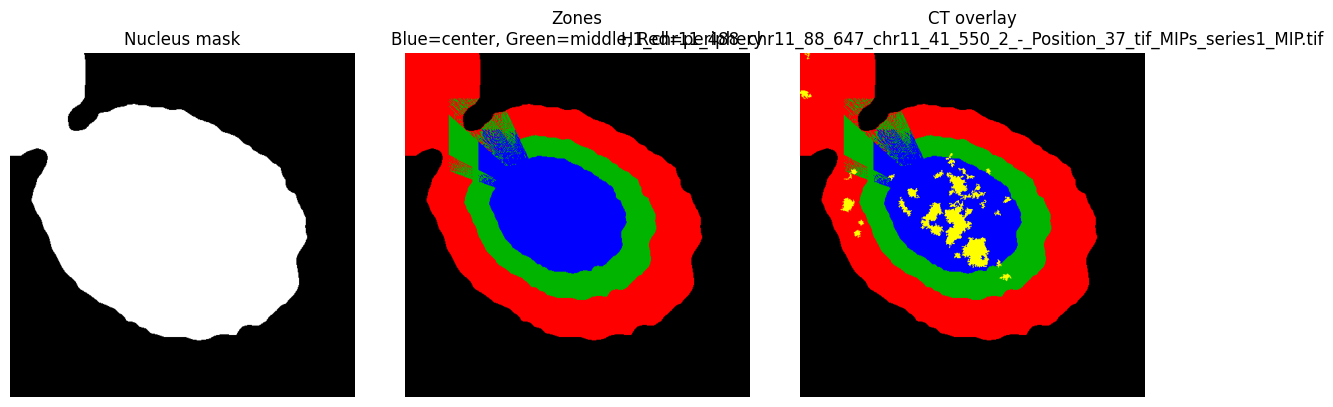

[3/11] Processing: H1_chr11_488_chr11_88_647_chr11_41_550_2_-_Position_52_tif_MIPs_series1_MIP.tif


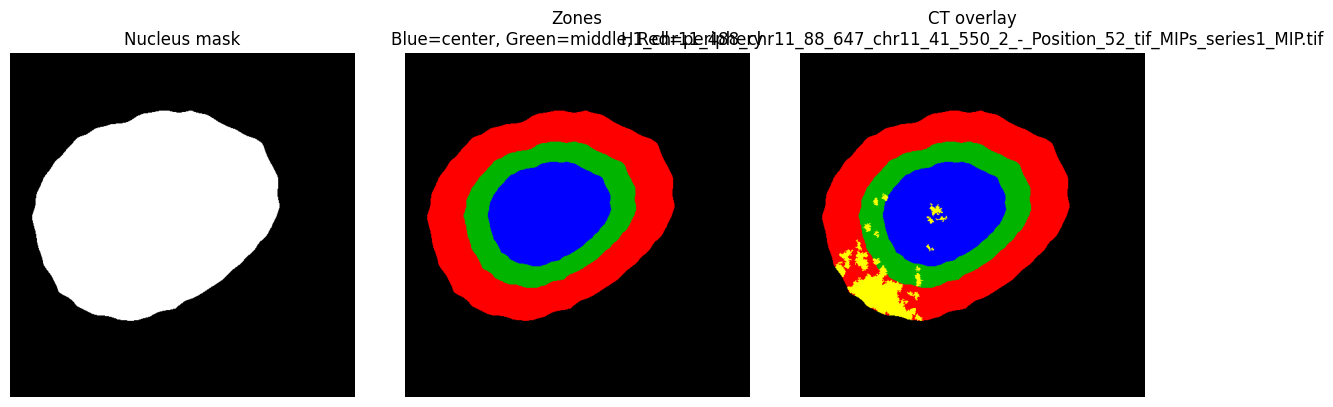

[4/11] Processing: iHep_chr11_488_chr11_11_647_chr11_41_550_1_-_Position_19_tif_MIPs_series1_MIP.tif
[5/11] Processing: iHep_chr11_488_chr11_11_647_chr11_41_550_1_-_Position_32_tif_MIPs_series1_MIP.tif
[6/11] Processing: mHep_chr11_488_chr11_107_647_chr11_119_550_2_-_Position_17_tif_MIPs__...p_chr11_488_chr11_107_647_chr11_119_550_2 - Position 17.tifseries1_MIP.tif
[7/11] Processing: mHep_chr11_488_chr11_107_647_chr11_119_550_2_-_Position_9_tif_MIPs_series1_MIP.tif
[8/11] Processing: mHep_chr11_488_chr11_11_647_chr11_41_550_2_-_Position_19_tif_MIPs_series1_MIP.tif
[9/11] Processing: mHep_chr11_488_chr11_88_647_chr11_41_550_2_-_Position_26_tif_MIPs_series1_MIP.tif
[10/11] Processing: mHep_chr11_488_chr11_88_647_chr11_41_550_2_-_Position_30_tif_MIPs_series1_MIP.tif
[11/11] Processing: mHep_chr11_488_chr11_88_647_chr11_41_550_2_-_Position_7_tif_MIPs_series1_MIP.tif


,CT_total_pixels,CT_periphery_pixels,CT_center_pixels,CT_middle_pixels,fraction_periphery,fraction_center,fraction_middle,image_name,Centroid_Y,Centroid_X,nucleus_area,ct_area
0,7971,20,5934,2017,0.002509,0.744449,0.253042,DE_chr11_488_chr11_88_647_chr11_41_550_2_-_Pos...,210.873848,213.930507,79864,7971
1,5803,572,5043,188,0.098570,0.869033,0.032397,H1_chr11_488_chr11_88_647_chr11_41_550_2_-_Pos...,229.668520,216.462005,118674,5803
2,5477,4603,335,539,0.840424,0.061165,0.098412,H1_chr11_488_chr11_88_647_chr11_41_550_2_-_Pos...,237.305368,211.802059,85081,5477
3,2739,800,877,1062,0.292077,0.320190,0.387733,iHep_chr11_488_chr11_11_647_chr11_41_550_1_-_P...,204.195036,230.197110,30861,2739
4,1984,1272,163,549,0.641129,0.082157,0.276714,iHep_chr11_488_chr11_11_647_chr11_41_550_1_-_P...,169.652495,219.442673,26532,1984


In [7]:
image_path = "/home/xiangru.huo-umw/scHiC/scripts/DNAfish_maximumtif/dot_test/"

results_df = analyze_folder_ct_localization(
    image_path=image_path,
    nucleus_channel=6,
    ct_channel=2,
    ct_threshold_percentile=90,
    ct_min_size=30,

    # skip weak/no CT signal
    min_ct_signal_pixels=10,
    min_ct_signal_intensity=0,

    # skip weak/no nuclear signal
    min_nuclear_signal_pixels=1000,
    min_nuclear_signal_intensity=0,

    show_first_n=3
)

results_df.head()

Found 70 files for stage H1
[1/70] Processing: H1_chr11_488_chr11_88_647_chr11_41_550_1_tif_MIPs_series1_MIP.tif
  [SKIP] H1_chr11_488_chr11_88_647_chr11_41_550_1_tif_MIPs_series1_MIP.tif -> No nuclear signal: only 721 pixels > 0
[2/70] Processing: H1_chr11_488_chr11_88_647_chr11_41_550_2_-_Position_11_tif_MIPs_series1_MIP.tif


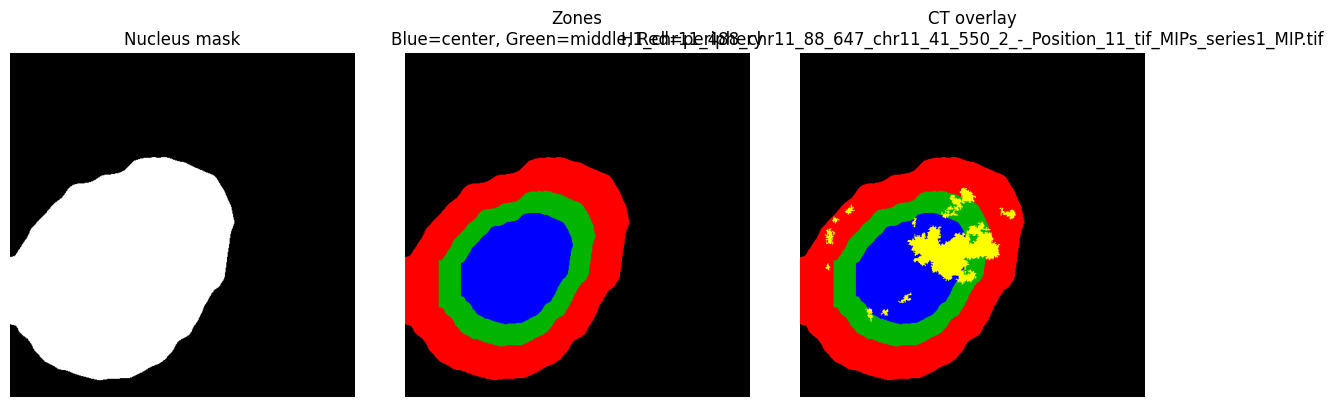

[3/70] Processing: H1_chr11_488_chr11_88_647_chr11_41_550_2_-_Position_18_tif_MIPs_series1_MIP.tif


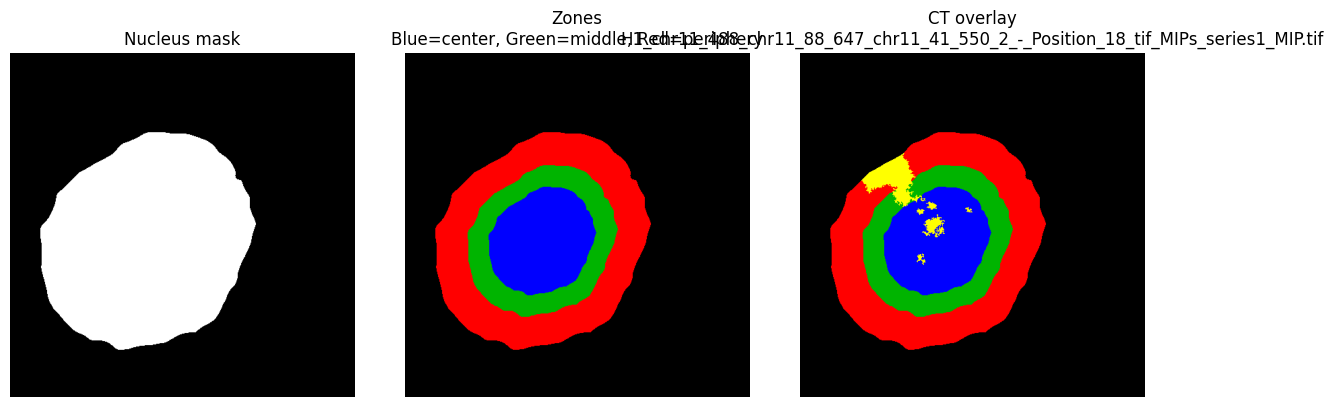

[4/70] Processing: H1_chr11_488_chr11_88_647_chr11_41_550_2_-_Position_1_tif_MIPs_series1_MIP.tif
  [SKIP] H1_chr11_488_chr11_88_647_chr11_41_550_2_-_Position_1_tif_MIPs_series1_MIP.tif -> No nuclear signal: only 810 pixels > 0
[5/70] Processing: H1_chr11_488_chr11_88_647_chr11_41_550_2_-_Position_20_tif_MIPs_series1_MIP.tif


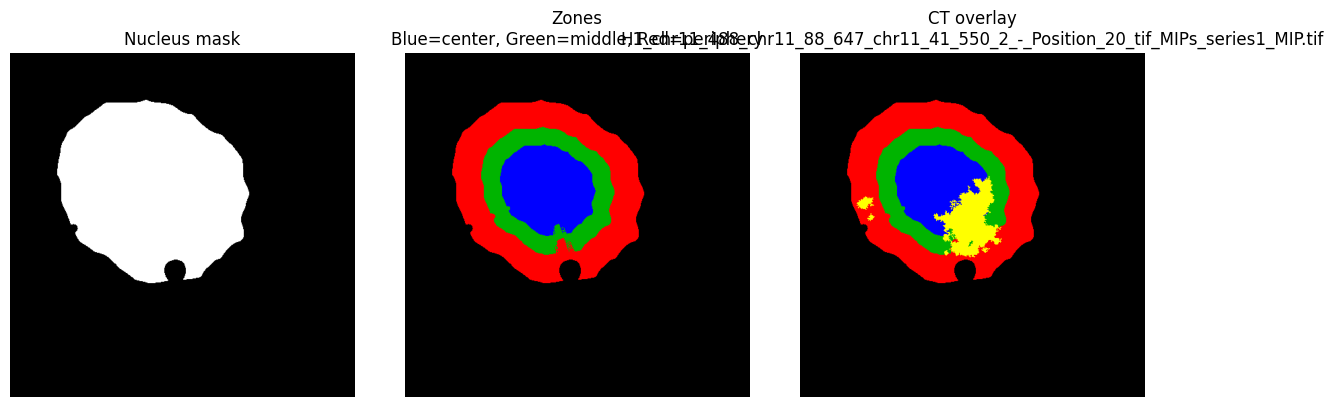

[6/70] Processing: H1_chr11_488_chr11_88_647_chr11_41_550_2_-_Position_21_tif_MIPs_series1_MIP.tif
[7/70] Processing: H1_chr11_488_chr11_88_647_chr11_41_550_2_-_Position_22_tif_MIPs_series1_MIP.tif
[8/70] Processing: H1_chr11_488_chr11_88_647_chr11_41_550_2_-_Position_23_tif_MIPs_series1_MIP.tif
  [SKIP] H1_chr11_488_chr11_88_647_chr11_41_550_2_-_Position_23_tif_MIPs_series1_MIP.tif -> No nucleus detected after thresholding.
[9/70] Processing: H1_chr11_488_chr11_88_647_chr11_41_550_2_-_Position_26_tif_MIPs_series1_MIP.tif
[10/70] Processing: H1_chr11_488_chr11_88_647_chr11_41_550_2_-_Position_27_tif_MIPs_series1_MIP.tif
[11/70] Processing: H1_chr11_488_chr11_88_647_chr11_41_550_2_-_Position_28_tif_MIPs_series1_MIP.tif
[12/70] Processing: H1_chr11_488_chr11_88_647_chr11_41_550_2_-_Position_29_tif_MIPs_series1_MIP.tif
[13/70] Processing: H1_chr11_488_chr11_88_647_chr11_41_550_2_-_Position_30_tif_MIPs_series1_MIP.tif
[14/70] Processing: H1_chr11_488_chr11_88_647_chr11_41_550_2_-_Position_

,CT_total_pixels,CT_periphery_pixels,CT_center_pixels,CT_middle_pixels,fraction_periphery,fraction_center,fraction_middle,image_name,Centroid_Y,Centroid_X,nucleus_area,ct_area,stage
0,7827,1263,4387,2177,0.161365,0.560496,0.278140,H1_chr11_488_chr11_88_647_chr11_41_550_2_-_Pos...,320.619831,165.593700,80822,7827,H1
1,3936,2391,891,654,0.607470,0.226372,0.166159,H1_chr11_488_chr11_88_647_chr11_41_550_2_-_Pos...,280.533970,202.995966,77347,3936,H1
2,6327,1204,3152,1971,0.190296,0.498182,0.311522,H1_chr11_488_chr11_88_647_chr11_41_550_2_-_Pos...,202.469121,210.607032,57791,6327,H1
3,6275,3824,398,2053,0.609402,0.063426,0.327171,H1_chr11_488_chr11_88_647_chr11_41_550_2_-_Pos...,237.373193,191.150969,65371,6275,H1
4,5832,1802,1676,2354,0.308985,0.287380,0.403635,H1_chr11_488_chr11_88_647_chr11_41_550_2_-_Pos...,221.676993,199.114132,54875,5832,H1


In [22]:
# Chr11_88 & Chr11_41
data_dir = "/home/xiangru.huo-umw/scHiC/scripts/DNAfish_maximumtif/Chr11_88_chr11_41/"

stage = 'H1' #change the stage you want to measure
tiff_files = [f for f in os.listdir(data_dir) if f.endswith(".tif") and f.startswith(stage)]

print(f"Found {len(tiff_files)} files for stage {stage}")

results = []

for i, f in enumerate(sorted(tiff_files)):
    image_file = os.path.join(data_dir, f)
    print(f"[{i+1}/{len(tiff_files)}] Processing: {f}")
    
    try:
        res = analyze_ct_localization_by_nuclear_zone(
            image_file=image_file,
            nucleus_channel=6,      # change if needed
            ct_channel=2,           # change if needed
            ct_threshold_percentile=85,
            ct_min_size=30,
            show_plot=(i < 5),
            
            # skip weak/no CT signal
            min_ct_signal_pixels=10,
            min_ct_signal_intensity=0,

            # skip weak/no nuclear signal
            min_nuclear_signal_pixels=1000,
            min_nuclear_signal_intensity=0,
        )
                
        res["stage"] = stage
        results.append(res)

    except Exception as e:
        print(f"  [SKIP] {f} -> {e}")

results_df = pd.DataFrame(results)

#save the results
out_file = os.path.join(data_dir, f"{stage}_CT_localization_blurred_contour_zones.csv")
results_df.to_csv(out_file, index=False)

results_df.head()

Found 59 files for stage DE
[1/59] Processing: DE_chr11_488_chr11_107_647_chr11_119_550_003_tif_MIPs_series1_MIP.tif


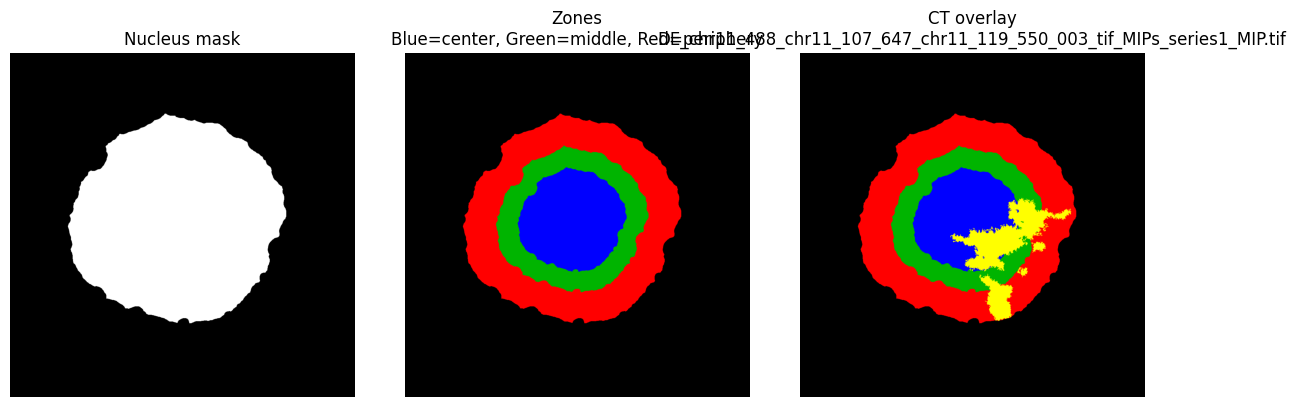

[2/59] Processing: DE_chr11_488_chr11_107_647_chr11_119_550_1_-_Position_60_tif_MIPs_series1_MIP.tif


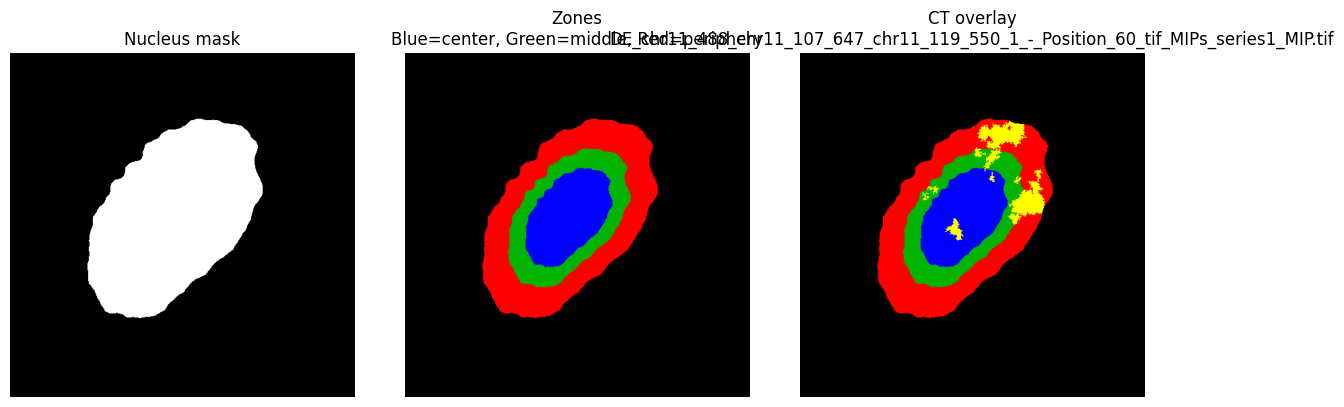

[3/59] Processing: DE_chr11_488_chr11_107_647_chr11_119_550_2_-_Position_10_tif_MIPs_series1_MIP.tif


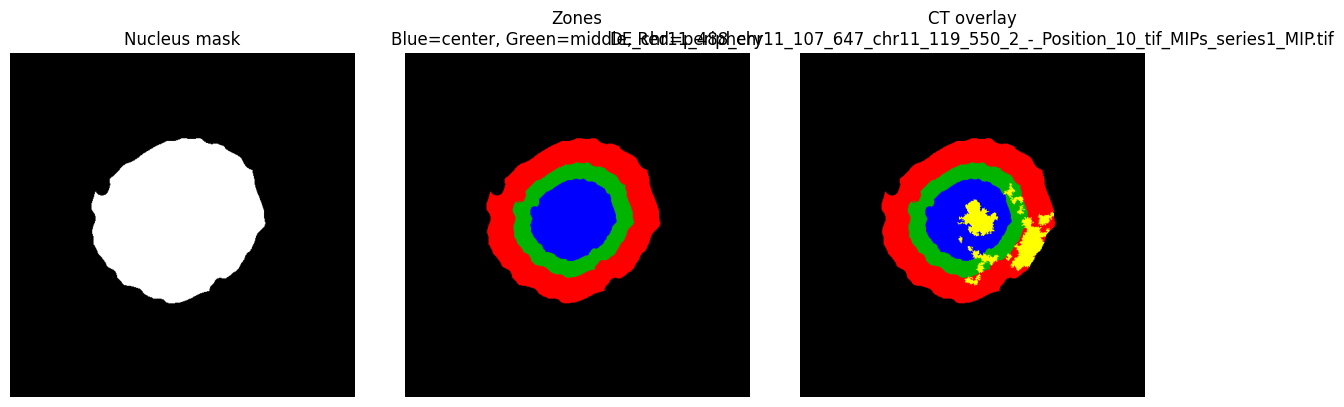

[4/59] Processing: DE_chr11_488_chr11_107_647_chr11_119_550_2_-_Position_12_tif_MIPs_series1_MIP.tif


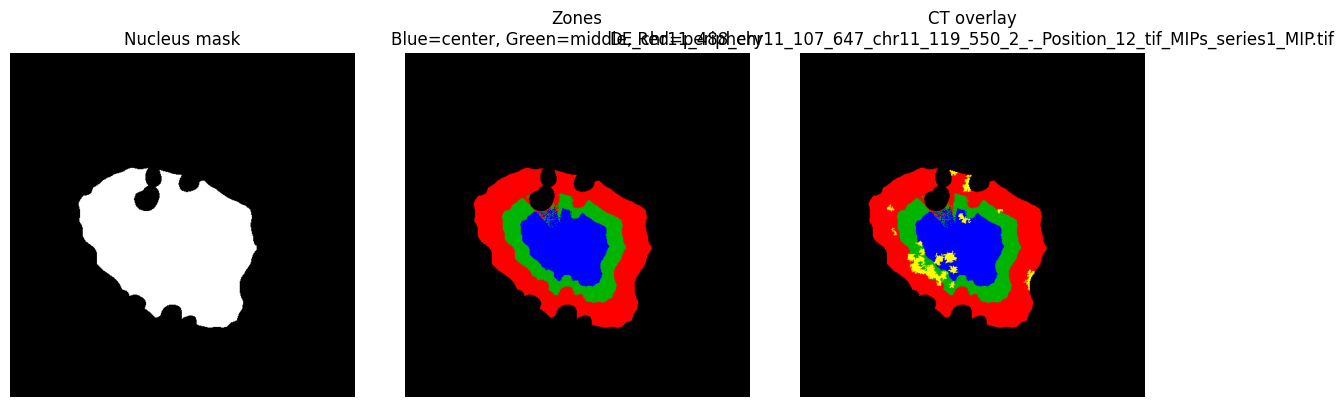

[5/59] Processing: DE_chr11_488_chr11_107_647_chr11_119_550_2_-_Position_13_tif_MIPs_series1_MIP.tif


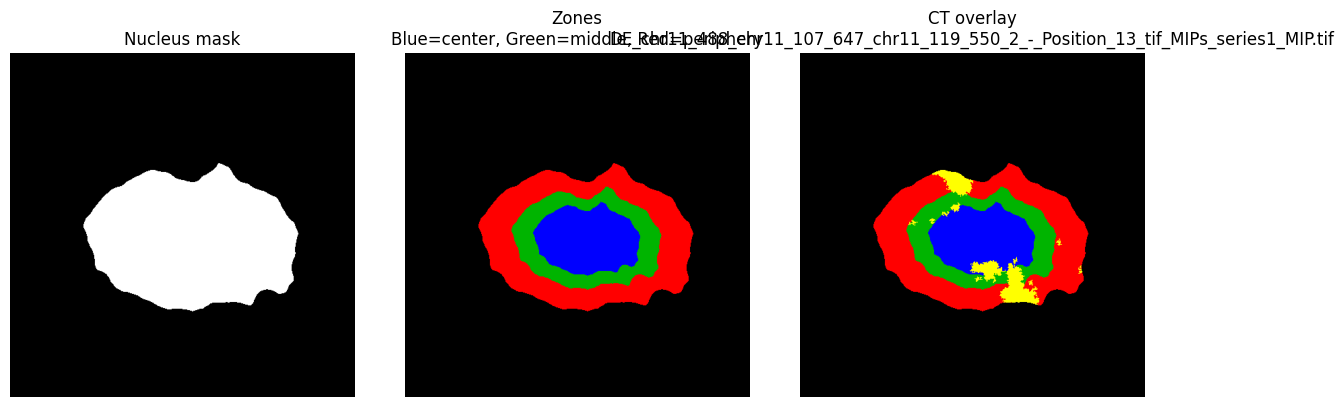

[6/59] Processing: DE_chr11_488_chr11_107_647_chr11_119_550_2_-_Position_14_tif_MIPs_series1_MIP.tif
[7/59] Processing: DE_chr11_488_chr11_107_647_chr11_119_550_2_-_Position_16_tif_MIPs_series1_MIP.tif
[8/59] Processing: DE_chr11_488_chr11_107_647_chr11_119_550_2_-_Position_17_tif_MIPs_series1_MIP.tif
[9/59] Processing: DE_chr11_488_chr11_107_647_chr11_119_550_2_-_Position_18_tif_MIPs_series1_MIP.tif
[10/59] Processing: DE_chr11_488_chr11_107_647_chr11_119_550_2_-_Position_1_tif_MIPs_series1_MIP.tif
[11/59] Processing: DE_chr11_488_chr11_107_647_chr11_119_550_2_-_Position_20_tif_MIPs_series1_MIP.tif
[12/59] Processing: DE_chr11_488_chr11_107_647_chr11_119_550_2_-_Position_21_tif_MIPs_series1_MIP.tif
[13/59] Processing: DE_chr11_488_chr11_107_647_chr11_119_550_2_-_Position_22_tif_MIPs_series1_MIP.tif
[14/59] Processing: DE_chr11_488_chr11_107_647_chr11_119_550_2_-_Position_23_tif_MIPs_series1_MIP.tif
[15/59] Processing: DE_chr11_488_chr11_107_647_chr11_119_550_2_-_Position_24_tif_MIPs_s

,CT_total_pixels,CT_periphery_pixels,CT_center_pixels,CT_middle_pixels,fraction_periphery,fraction_center,fraction_middle,image_name,Centroid_Y,Centroid_X,nucleus_area,ct_area,stage
0,34301,9228,15284,9789,0.269030,0.445585,0.285385,DE_chr11_488_chr11_107_647_chr11_119_550_003_t...,499.251418,495.926070,293833,34301,DE
1,4683,3171,432,1080,0.677130,0.092249,0.230621,DE_chr11_488_chr11_107_647_chr11_119_550_1_-_P...,243.442419,241.095758,51797,4683,DE
2,5043,2383,1860,800,0.472536,0.368828,0.158636,DE_chr11_488_chr11_107_647_chr11_119_550_2_-_P...,247.509107,249.171295,45845,5043,DE
3,2083,784,586,713,0.376380,0.281325,0.342295,DE_chr11_488_chr11_107_647_chr11_119_550_2_-_P...,286.033202,239.766631,41775,2083,DE
4,4258,2461,835,962,0.577971,0.196101,0.225928,DE_chr11_488_chr11_107_647_chr11_119_550_2_-_P...,278.534004,270.515909,51009,4258,DE


In [24]:
# Chr11_107 & Chr11_119
data_dir = "/home/xiangru.huo-umw/scHiC/scripts/DNAfish_maximumtif/Chr11_107_chr11_119/"

stage = 'DE' #change the stage you want to measure
tiff_files = [f for f in os.listdir(data_dir) if f.endswith(".tif") and f.startswith(stage)]

print(f"Found {len(tiff_files)} files for stage {stage}")

results = []

for i, f in enumerate(sorted(tiff_files)):
    image_file = os.path.join(data_dir, f)
    print(f"[{i+1}/{len(tiff_files)}] Processing: {f}")
    
    try:
        res = analyze_ct_localization_by_nuclear_zone(
            image_file=image_file,
            nucleus_channel=6,      # change if needed
            ct_channel=2,           # change if needed
            ct_threshold_percentile=85,
            ct_min_size=30,
            
            # skip weak/no CT signal
            min_ct_signal_pixels=10,
            min_ct_signal_intensity=0,

            # skip weak/no nuclear signal
            min_nuclear_signal_pixels=1000,
            min_nuclear_signal_intensity=0,
            
            show_plot=(i < 5)
        )
        res["stage"] = stage
        results.append(res)

    except Exception as e:
        print(f"  [SKIP] {f} -> {e}")

results_df = pd.DataFrame(results)

#save the results
out_file = os.path.join(data_dir, f"{stage}_CT_localization_blurred_contour_zones.csv")
results_df.to_csv(out_file, index=False)

results_df.head()

Found 73 files for stage DE
[1/73] Processing: DE_chr11_488_chr11_11_647_chr11_chr41_550_1_-_Position_10_tif_MIPs_series1_MIP.tif


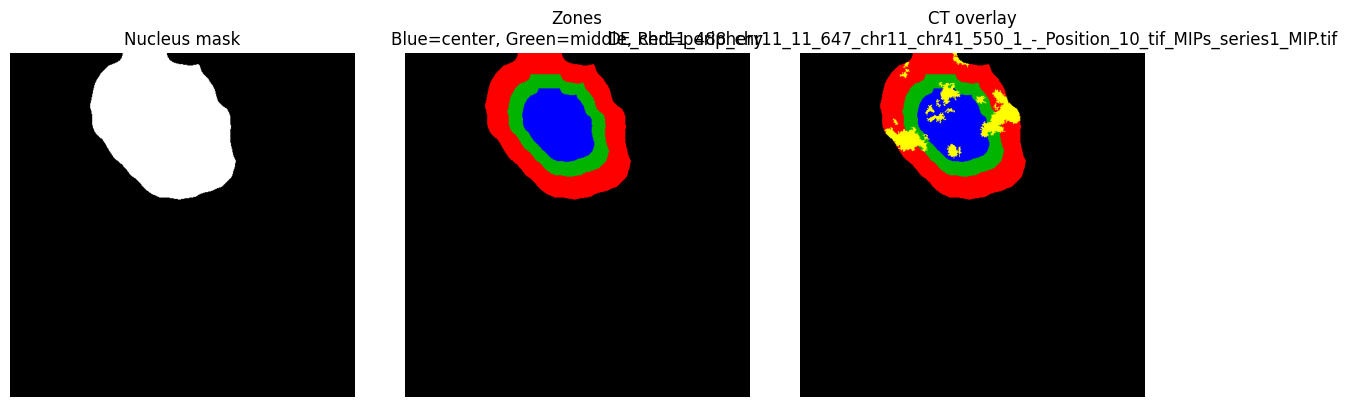

[2/73] Processing: DE_chr11_488_chr11_11_647_chr11_chr41_550_1_-_Position_11_tif_MIPs_series1_MIP.tif


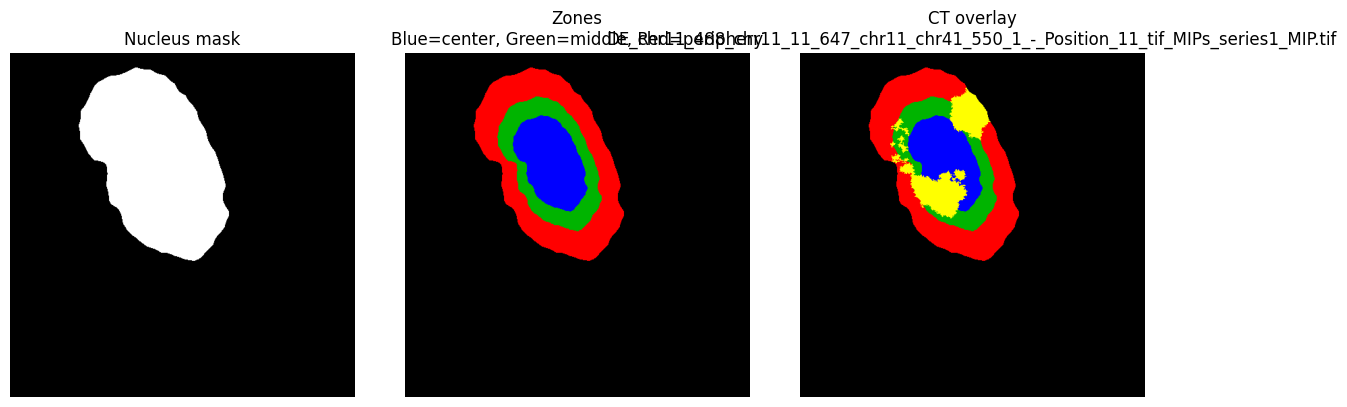

[3/73] Processing: DE_chr11_488_chr11_11_647_chr11_chr41_550_1_-_Position_12_tif_MIPs_series1_MIP.tif


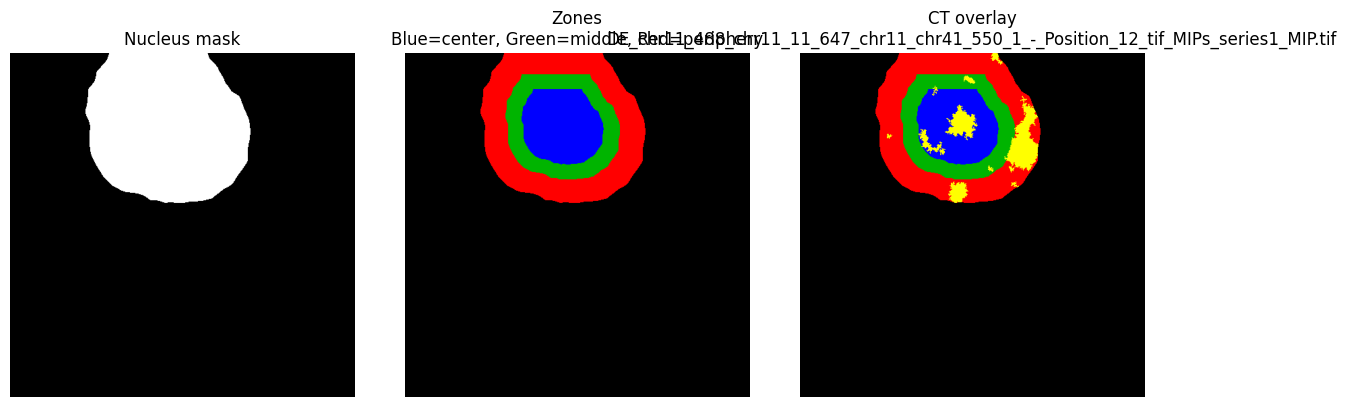

[4/73] Processing: DE_chr11_488_chr11_11_647_chr11_chr41_550_1_-_Position_13_tif_MIPs_series1_MIP.tif


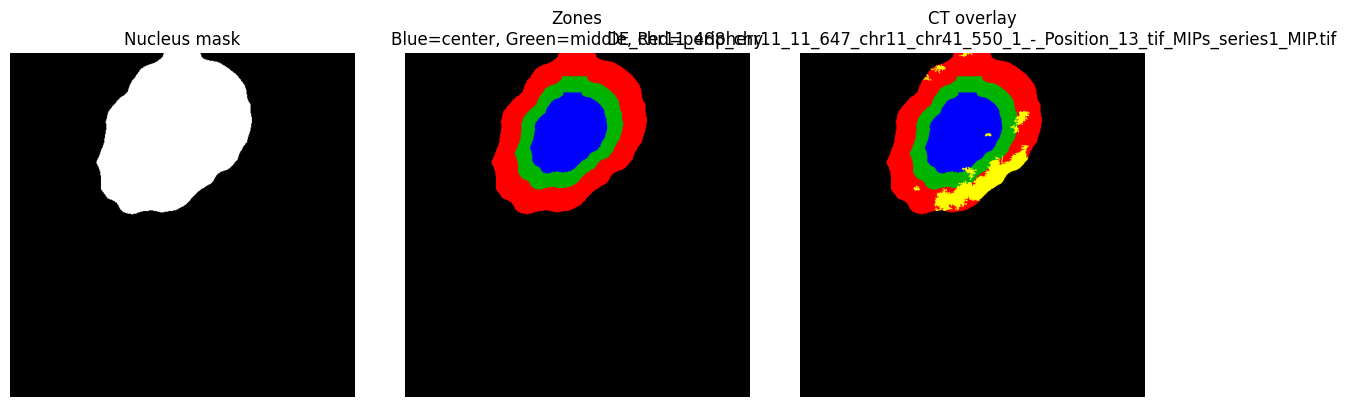

[5/73] Processing: DE_chr11_488_chr11_11_647_chr11_chr41_550_1_-_Position_14_tif_MIPs_series1_MIP.tif


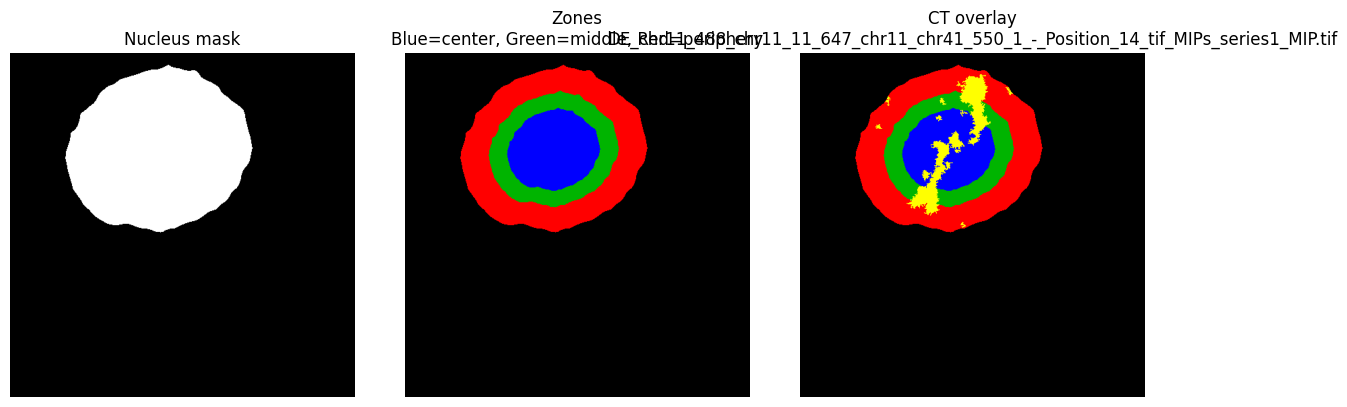

[6/73] Processing: DE_chr11_488_chr11_11_647_chr11_chr41_550_1_-_Position_15_tif_MIPs_series1_MIP.tif
[7/73] Processing: DE_chr11_488_chr11_11_647_chr11_chr41_550_1_-_Position_16_tif_MIPs_series1_MIP.tif
[8/73] Processing: DE_chr11_488_chr11_11_647_chr11_chr41_550_1_-_Position_17_tif_MIPs_series1_MIP.tif
[9/73] Processing: DE_chr11_488_chr11_11_647_chr11_chr41_550_1_-_Position_18_tif_MIPs_series1_MIP.tif
[10/73] Processing: DE_chr11_488_chr11_11_647_chr11_chr41_550_1_-_Position_19_aivia_tif_MIPs__DE_chr11_488_chr11_11_647_chr11_chr41_550_1 - Position 19.aivi..._488_chr11_11_647_chr11_chr41_550_1 - Position 19.aivia.tifseries1_MIP.tif
  [SKIP] DE_chr11_488_chr11_11_647_chr11_chr41_550_1_-_Position_19_aivia_tif_MIPs__DE_chr11_488_chr11_11_647_chr11_chr41_550_1 - Position 19.aivi..._488_chr11_11_647_chr11_chr41_550_1 - Position 19.aivia.tifseries1_MIP.tif -> No nucleus detected after thresholding.
[11/73] Processing: DE_chr11_488_chr11_11_647_chr11_chr41_550_1_-_Position_19_tif_MIPs_serie

[59/73] Processing: DE_chr11_488_chr11_11_647_chr11_chr41_550_1_-_Position_62_tif_MIPs_series1_MIP.tif
[60/73] Processing: DE_chr11_488_chr11_11_647_chr11_chr41_550_1_-_Position_63_tif_MIPs_series1_MIP.tif
[61/73] Processing: DE_chr11_488_chr11_11_647_chr11_chr41_550_1_-_Position_64_tif_MIPs_series1_MIP.tif
[62/73] Processing: DE_chr11_488_chr11_11_647_chr11_chr41_550_1_-_Position_65_aivia_tif_MIPs__DE_chr11_488_chr11_11_647_chr11_chr41_550_1 - Position 65.aivi..._488_chr11_11_647_chr11_chr41_550_1 - Position 65.aivia.tifseries1_MIP.tif
  [SKIP] DE_chr11_488_chr11_11_647_chr11_chr41_550_1_-_Position_65_aivia_tif_MIPs__DE_chr11_488_chr11_11_647_chr11_chr41_550_1 - Position 65.aivi..._488_chr11_11_647_chr11_chr41_550_1 - Position 65.aivia.tifseries1_MIP.tif -> No nucleus detected after thresholding.
[63/73] Processing: DE_chr11_488_chr11_11_647_chr11_chr41_550_1_-_Position_65_tif_MIPs_series1_MIP.tif
  [SKIP] DE_chr11_488_chr11_11_647_chr11_chr41_550_1_-_Position_65_tif_MIPs_series1_MIP.

,CT_total_pixels,CT_periphery_pixels,CT_center_pixels,CT_middle_pixels,fraction_periphery,fraction_center,fraction_middle,image_name,Centroid_Y,Centroid_X,nucleus_area,ct_area,stage
0,4555,2296,1187,1072,0.504061,0.260593,0.235346,DE_chr11_488_chr11_11_647_chr11_chr41_550_1_-_...,107.739750,227.967677,34805,4555,DE
1,7328,2284,2350,2694,0.311681,0.320688,0.367631,DE_chr11_488_chr11_11_647_chr11_chr41_550_1_-_...,163.319303,216.604858,42195,7328,DE
2,5423,3404,1708,311,0.627697,0.314955,0.057348,DE_chr11_488_chr11_11_647_chr11_chr41_550_1_-_...,109.403427,232.040223,45049,5423,DE
3,4573,4137,67,369,0.904658,0.014651,0.080691,DE_chr11_488_chr11_11_647_chr11_chr41_550_1_-_...,119.764889,241.719466,40045,4573,DE
4,5332,1578,2105,1649,0.295949,0.394786,0.309265,DE_chr11_488_chr11_11_647_chr11_chr41_550_1_-_...,145.295848,219.914000,50837,5332,DE


In [25]:
# Chr11_11 & Chr11_41
data_dir = "/home/xiangru.huo-umw/scHiC/scripts/DNAfish_maximumtif/Chr11_11_chr11_41/"

stage = 'DE' #change the stage you want to measure
tiff_files = [f for f in os.listdir(data_dir) if f.endswith(".tif") and f.startswith(stage)]

print(f"Found {len(tiff_files)} files for stage {stage}")

results = []

for i, f in enumerate(sorted(tiff_files)):
    image_file = os.path.join(data_dir, f)
    print(f"[{i+1}/{len(tiff_files)}] Processing: {f}")
    
    try:
        res = analyze_ct_localization_by_nuclear_zone(
            image_file=image_file,
            nucleus_channel=6,      # change if needed
            ct_channel=2,           # change if needed
            ct_threshold_percentile=80,
            ct_min_size=30,
            
            # skip weak/no CT signal
            min_ct_signal_pixels=10,
            min_ct_signal_intensity=0,

            # skip weak/no nuclear signal
            min_nuclear_signal_pixels=1000,
            min_nuclear_signal_intensity=0,
            
            show_plot=(i < 5)
        )
        res["stage"] = stage
        results.append(res)

    except Exception as e:
        print(f"  [SKIP] {f} -> {e}")

results_df = pd.DataFrame(results)

#save the results
out_file = os.path.join(data_dir, f"{stage}_CT_localization_blurred_contour_zones.csv")
results_df.to_csv(out_file, index=False)

results_df.head()

In [9]:
import os
import pandas as pd
from pandas.errors import EmptyDataError
import matplotlib.pyplot as plt

stages = ['H1', 'DE', 'HB', 'iHep', 'mHep']

file_paths_chr11 = {
    "Chr11_88_chr11_41": "/home/xiangru.huo-umw/scHiC/scripts/DNAfish_maximumtif/Chr11_88_chr11_41/{stage}_CT_localization_blurred_contour_zones.csv",
    "Chr11_11_chr11_41": "/home/xiangru.huo-umw/scHiC/scripts/DNAfish_maximumtif/Chr11_11_chr11_41/{stage}_CT_localization_blurred_contour_zones.csv",
    "Chr11_107_chr11_119": "/home/xiangru.huo-umw/scHiC/scripts/DNAfish_maximumtif/Chr11_107_chr11_119/{stage}_CT_localization_blurred_contour_zones.csv",
}

def load_one_csv(path, stage, dataset):
    if not os.path.exists(path) or os.path.getsize(path) == 0:
        return None
    try:
        df = pd.read_csv(path)
        if df.shape[1] == 0:
            return None
        df["stage"] = stage
        df["dataset"] = dataset
        return df
    except (EmptyDataError, pd.errors.ParserError):
        return None

Chr11 = {
    name: pd.concat(
        [
            df for stage in stages
            if (df := load_one_csv(path_template.format(stage=stage), stage, name)) is not None
        ],
        ignore_index=True
    )
    for name, path_template in file_paths_chr11.items()
}

# remove bad-quality stages
#if "Chr11_11_chr11_41" in Chr11:
#    Chr11["Chr11_11_chr11_41"] = Chr11["Chr11_11_chr11_41"][
#        ~Chr11["Chr11_11_chr11_41"]["stage"].isin(["H1", "DE"])
#    ].copy()

In [10]:
Chr11

{'Chr11_88_chr11_41':      CT_total_pixels  CT_periphery_pixels  CT_center_pixels  CT_middle_pixels  \
 0               7827                 1263              4387              2177   
 1               3936                 2391               891               654   
 2               6327                 1204              3152              1971   
 3               6275                 3824               398              2053   
 4               5832                 1802              1676              2354   
 ..               ...                  ...               ...               ...   
 219             1312                  778                34               500   
 220             2215                 1068               391               756   
 221             1651                  571               909               171   
 222             2768                 2299               165               304   
 223             3660                 1632              1083               94

In [11]:
#concatenate into same table
Chr11_all = pd.concat(Chr11.values(), ignore_index=True)
Chr11_all.head()

,CT_total_pixels,CT_periphery_pixels,CT_center_pixels,CT_middle_pixels,fraction_periphery,fraction_center,fraction_middle,image_name,Centroid_Y,Centroid_X,nucleus_area,ct_area,stage,dataset
0,7827,1263,4387,2177,0.161365,0.560496,0.278140,H1_chr11_488_chr11_88_647_chr11_41_550_2_-_Pos...,320.619831,165.593700,80822,7827,H1,Chr11_88_chr11_41
1,3936,2391,891,654,0.607470,0.226372,0.166159,H1_chr11_488_chr11_88_647_chr11_41_550_2_-_Pos...,280.533970,202.995966,77347,3936,H1,Chr11_88_chr11_41
2,6327,1204,3152,1971,0.190296,0.498182,0.311522,H1_chr11_488_chr11_88_647_chr11_41_550_2_-_Pos...,202.469121,210.607032,57791,6327,H1,Chr11_88_chr11_41
3,6275,3824,398,2053,0.609402,0.063426,0.327171,H1_chr11_488_chr11_88_647_chr11_41_550_2_-_Pos...,237.373193,191.150969,65371,6275,H1,Chr11_88_chr11_41
4,5832,1802,1676,2354,0.308985,0.287380,0.403635,H1_chr11_488_chr11_88_647_chr11_41_550_2_-_Pos...,221.676993,199.114132,54875,5832,H1,Chr11_88_chr11_41


In [12]:
stage_order = ['H1', 'DE', 'HB', 'iHep', 'mHep']

plot_df = (
    Chr11_all
    .groupby("stage")[["fraction_center", "fraction_middle", "fraction_periphery"]]
    .mean()
    .reindex(stage_order)
)

plot_df

,fraction_center,fraction_middle,fraction_periphery
stage,,,
H1,0.424438,0.212765,0.362797
DE,0.248690,0.234549,0.516760
HB,0.270610,0.252760,0.476630
iHep,0.313741,0.232026,0.454232
mHep,0.265232,0.242328,0.492440


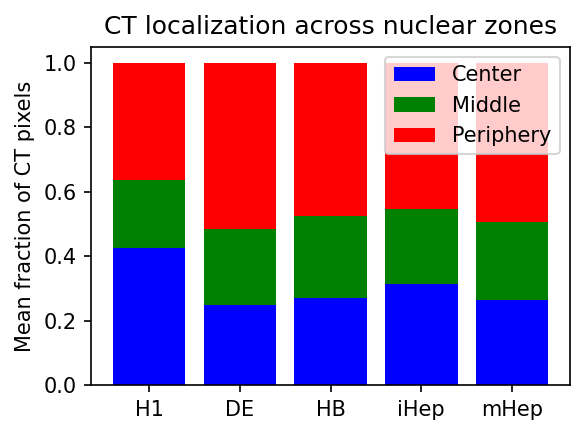

In [13]:
#barplot
plt.figure(figsize=(4, 3), dpi=150)

plt.bar(plot_df.index, plot_df["fraction_center"], label="Center", color="blue")
plt.bar(
    plot_df.index,
    plot_df["fraction_middle"],
    bottom=plot_df["fraction_center"],
    label="Middle",
    color="green"
)
plt.bar(
    plot_df.index,
    plot_df["fraction_periphery"],
    bottom=plot_df["fraction_center"] + plot_df["fraction_middle"],
    label="Periphery",
    color="red"
)

plt.ylabel("Mean fraction of CT pixels")
plt.title("CT localization across nuclear zones")
plt.legend()
plt.tight_layout()
output_path = "/home/xiangru.huo-umw/scHiC/scripts/plot2/chr11_CT_nuclear_distribution.pdf"
plt.savefig(output_path, dpi=150, format="pdf", bbox_inches="tight")

plt.show()

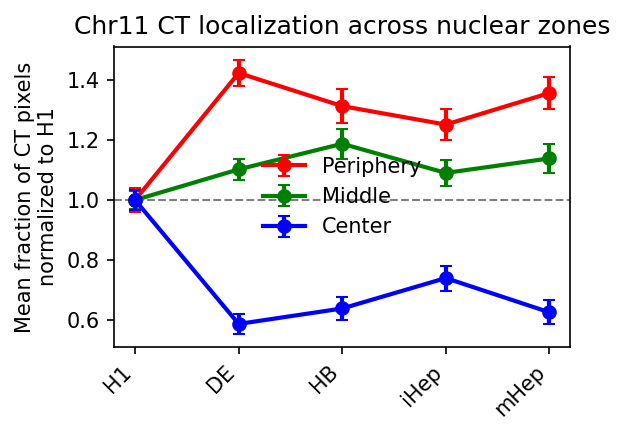

In [14]:
#line plot
import numpy as np
import matplotlib.pyplot as plt

stage_order = ['H1', 'DE', 'HB', 'iHep', 'mHep']

cols = ["fraction_center", "fraction_middle", "fraction_periphery"]

# Mean
mean_df = (
    Chr11_all
    .groupby("stage")[cols]
    .mean()
    .reindex(stage_order)
)

# Standard error
se_df = (
    Chr11_all
    .groupby("stage")[cols]
    .sem()
    .reindex(stage_order)
)

# Normalize to ES/H1
es_label = "H1"

mean_norm = mean_df / mean_df.loc[es_label]
se_norm = se_df / mean_df.loc[es_label]

plt.figure(figsize=(4, 3), dpi=150)

plt.errorbar(
    mean_norm.index,
    mean_norm["fraction_periphery"],
    yerr=se_norm["fraction_periphery"],
    marker="o",
    linewidth=2,
    capsize=3,
    label="Periphery",
    color="red"
)

plt.errorbar(
    mean_norm.index,
    mean_norm["fraction_middle"],
    yerr=se_norm["fraction_middle"],
    marker="o",
    linewidth=2,
    capsize=3,
    label="Middle",
    color="green"
)

plt.errorbar(
    mean_norm.index,
    mean_norm["fraction_center"],
    yerr=se_norm["fraction_center"],
    marker="o",
    linewidth=2,
    capsize=3,
    label="Center",
    color="blue"
)

plt.axhline(1, color="gray", linestyle="--", linewidth=1)

plt.ylabel("Mean fraction of CT pixels\nnormalized to H1")
plt.title("Chr11 CT localization across nuclear zones")

plt.xticks(rotation=45, ha="right")
plt.legend(frameon=False)
plt.tight_layout()

output_path = "/home/xiangru.huo-umw/scHiC/scripts/plot2/chr11_CT_nuclear_distribution_line_norm_to_H1_SE.pdf"
plt.savefig(output_path, dpi=150, format="pdf", bbox_inches="tight")

plt.show()